# Assignment 2(due on 10/28)

## Student: 李佳晨（12632724），Github: LJC-new

## 批改人：张鹏

## 得分：94/100 

In [1]:
import pandas as pd
import numpy as np
#1.1
Sig_Eqs = pd.read_csv(
    "/home/zhangp/桌面/A2/earthquakes-2026-10-30_17-09-02_+0800.tsv",  # 助教更改读取路径
    sep="\t",
    low_memory=False
)

# 解决历史名称不同
country_map = {
    "TURKEY-CIS": "TURKEY",
    "USSR": "RUSSIA",
    "BURMA": "MYANMAR (BURMA)",
    "USA TERRITORY": "USA",
    "UK TERRITORY": "UK",
    "CZECHOSLOVAKIA": "CZECH REPUBLIC",
    "YUGOSLAVIA": "SERBIA",
}
Sig_Eqs["Country_std"] = (
    Sig_Eqs["Country"]
    .map(country_map)
    .fillna(Sig_Eqs["Country"])
)

# 死亡人数转数值
Sig_Eqs["Total Deaths"] = pd.to_numeric(
    Sig_Eqs["Total Deaths"], errors="coerce"
).fillna(0)

#按标准化国家分组求和，降序取前 20
deaths_by_country = (
    Sig_Eqs.groupby("Country_std")["Total Deaths"]
    .sum()
    .sort_values(ascending=False)
)

top20 = deaths_by_country.head(20)
print("Top 20 countries by total earthquake deaths:")
print(top20)


Top 20 countries by total earthquake deaths:
Country_std
CHINA           2106542.0
TURKEY          1008867.0
IRAN             761641.0
ITALY            417297.0
SYRIA            358326.0
HAITI            323782.0
JAPAN            319510.0
AZERBAIJAN       319251.0
INDONESIA        283485.0
ARMENIA          175000.0
PAKISTAN         143714.0
ECUADOR          134445.0
TURKMENISTAN     110412.0
PERU              97009.0
GREECE            83658.0
PORTUGAL          82572.0
IRAQ              70200.0
CHILE             70175.0
INDIA             63413.0
ISRAEL            58368.0
Name: Total Deaths, dtype: float64


Mean annual count before 1900: 1.99
Mean annual count from 1900 onward: 19.49


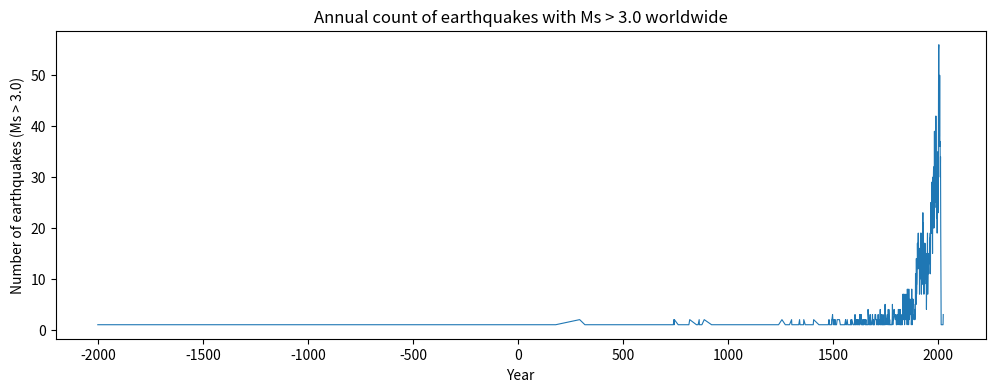

In [2]:
# 1.2 
# 把 Ms 转成数值，非数值变 NaN
Sig_Eqs["Ms"] = pd.to_numeric(Sig_Eqs["Ms"], errors="coerce")

# 只保留 Ms > 3.0 的记录
ms_gt3 = Sig_Eqs[Sig_Eqs["Ms"] > 3.0]

# 按 Year 分组计数（size() 返回每组的行数，即每年地震条数）
# sort_index() 年份从小到大排列
counts_per_year = ms_gt3.groupby("Year").size().sort_index()

counts_per_year.plot(
    kind="line",
    figsize=(12, 4),
    title="Annual count of earthquakes with Ms > 3.0 worldwide",
    xlabel="Year",
    ylabel="Number of earthquakes (Ms > 3.0)",
    linewidth=0.8
)

years = counts_per_year.index.to_numpy()   # 年份数组
vals  = counts_per_year.to_numpy()         # 每年计数数组
early = vals[years < 1900].mean() if (years < 1900).any() else np.nan
late  = vals[years >= 1900].mean() if (years >= 1900).any() else np.nan
print(f"Mean annual count before 1900: {early:.2f}")
print(f"Mean annual count from 1900 onward: {late:.2f}")

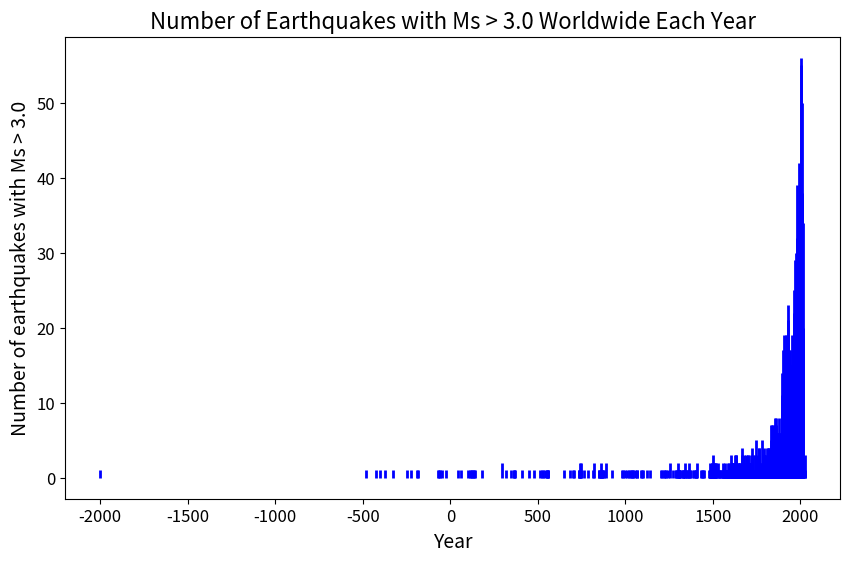

In [4]:
import matplotlib.pyplot as plt
#1.2 助教添加
# 筛选出震级大于6.0的地震
large_quakes = Sig_Eqs[Sig_Eqs['Ms'] > 3.0]

# 按年份对数据进行分组，并得到每年的地震次数
quakes_by_year = large_quakes.groupby('Year')['Ms'].count()

plt.figure(figsize=(10, 6))
plt.vlines(quakes_by_year.index, ymin=0, ymax=quakes_by_year.values, color='blue', linewidth=2)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Number of earthquakes with Ms > 3.0', fontsize=14)
plt.title('Number of Earthquakes with Ms > 3.0 Worldwide Each Year', fontsize=16)
plt.tick_params(axis='both', which='major', labelsize=12)

# Displaying the plot
plt.show()

In [6]:
def CountEq_LargestEq(country):
  
    #取出该国的所有记录，该国地震总数
    sub = Sig_Eqs[Sig_Eqs["Country"] == country]
    n_eq = len(sub)                      

    #没有记录直接返回
    if n_eq == 0:
        return 0, None

    #过滤掉 Ms 缺失的记录，找最大地震要用 Ms 比较，缺失 Ms 的行不能参与比较。
    sub_valid = sub[sub["Ms"].notna()]
    if len(sub_valid) == 0:
        # 有记录但所有 Ms 都缺失
        return n_eq, None

    #用 numpy.argmax 找 Ms 最大的位置
    ms_vals = sub_valid["Ms"].to_numpy()
    idx_max = int(np.argmax(ms_vals))
    
     # 定位到最大地震那一行
    row = sub_valid.iloc[idx_max]       

    #拼接日期
    def fmt(v):
        return "" if pd.isna(v) else str(int(v))

    date = "-".join([fmt(row["Year"]), fmt(row["Mo"]), fmt(row["Dy"])]).strip("-")

    #地点列名是 "Location Name"
    location = row["Location Name"] if "Location Name" in sub_valid.columns else ""

    #返回 (总数, (日期, 地点, Ms))
    return n_eq, (date, location, row["Ms"])

# 对所有国家应用该函数
results = []
# dropna().unique()：去掉空、重复国家名
for c in Sig_Eqs["Country"].dropna().unique():
    n_eq, largest = CountEq_LargestEq(c)
    results.append((c, n_eq, largest))

# 组装成 DataFrame，按地震总数降序排序
results_df = (
    pd.DataFrame(results, columns=["Country", "N_EARTHQUAKES", "LARGEST_EQ"])
    .sort_values("N_EARTHQUAKES", ascending=False)
    .reset_index(drop=True)
)

# 让 pandas 显示更多行，方便查看完整结果
pd.set_option("display.max_rows", 300)
print(results_df)

                                          Country  N_EARTHQUAKES  \
0                                           CHINA            627   
1                                           JAPAN            429   
2                                       INDONESIA            427   
3                                            IRAN            385   
4                                          TURKEY            359   
5                                           ITALY            338   
6                                          GREECE            296   
7                                             USA            283   
8                                     PHILIPPINES            233   
9                                          MEXICO            217   
10                                          CHILE            200   
11                                           PERU            195   
12                                         RUSSIA            159   
13                               PAPUA NEW GUINE

### 第一题代码运行正常，可以输出正确结果，报告中也展示了输出内容，也针对问题给出文字分析。第二问绘图有一点点问题，没有数据的年份不应该有数据，建议绘制竖线图或者删除NAN值后绘图，见上面代码助教添加代码


### 得分：23/25
### --------------------------------------------------------------------------------------------

/tmp/ipykernel_1556716/1634573176.py:3: DtypeWarning: Columns (4,8,9,10,11,14,15,24,25,27,29,31,34,37,38,40,41,45,49,50) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/home/zhangp/桌面/A2/Baoan_Weather_1998_2022.csv")  # 助教更改读取路径


有效TMP条数: 234877 / 235674
质量代码分布: {'1': 234863, '2': 13, '5': 1}
最终有效记录数: 234863
月数: 298
Linear trend slope: 0.003235 °C/month
Approx. trend per decade: 0.388 °C/decade
Total change over period: 0.961 °C


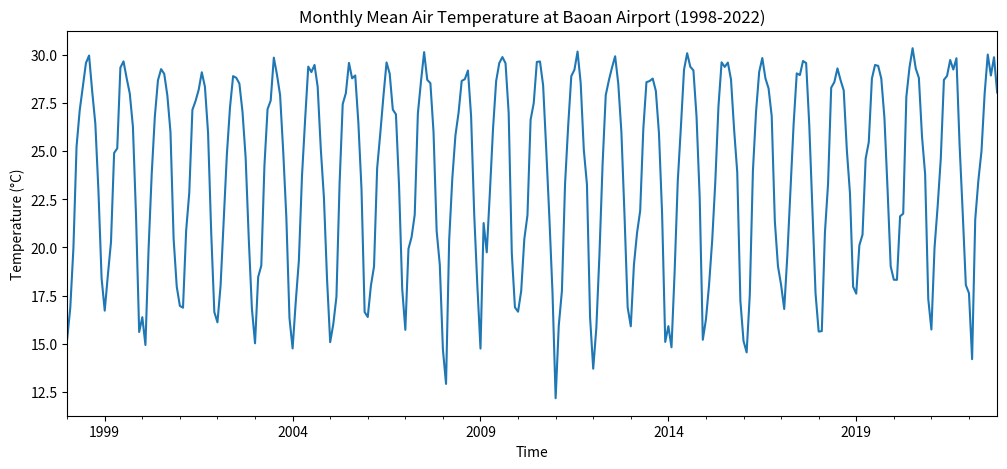

In [7]:
import pandas as pd
import numpy as np
df = pd.read_csv("/home/zhangp/桌面/A2/Baoan_Weather_1998_2022.csv")  # 助教更改读取路径

# TMP 
# TMP 格式: "+0186,1"  => 数值 +0186 (0.1°C, 即 18.6°C), 质量代码 1
tmp = df['TMP'].astype(str).str.strip()

# 按逗号拆成数值、质量代码两部分
parts = tmp.str.split(',', n=1, expand=True)

# 有效条件: 有两部分, 第一部分是 符号+4位数字, 第二部分是单个数字
valid = (
    parts[0].str.match(r'^[+-]\d{4}$', na=False) &
    parts[1].str.match(r'^\d$', na=False) &
    (parts[0].str[1:5] != '9999')          # 9999 = 缺失值
)
print('有效TMP条数:', valid.sum(), '/', len(tmp))

val_str = parts[0][valid]
sign = val_str.str[0]
value = val_str.str[1:5].astype(float) / 10.0

#按符号生成温度 Series
temp_c = pd.Series(np.where(sign == '-', -value, value), index=val_str.index)

quality = parts[1][valid]
print('质量代码分布:', quality.value_counts().to_dict())

#只保留质量代码 1 (通过全部质检)
mask_qc = quality == '1'
df_valid = df.loc[mask_qc[mask_qc].index].copy()
df_valid['TEMP_C'] = temp_c[mask_qc]

#解析 DATE
# DATE 形如 "1998-01-01T00:00:00"
df_valid['DATE_DT'] = pd.to_datetime(df_valid['DATE'], errors='coerce')
df_valid = df_valid.dropna(subset=['DATE_DT', 'TEMP_C'])
print('最终有效记录数:', len(df_valid))
#月平均
df_valid['YearMonth'] = df_valid['DATE_DT'].dt.to_period('M')
monthly_mean = df_valid.groupby('YearMonth')['TEMP_C'].mean()
print('月数:', len(monthly_mean))
# 化图 
monthly_mean.index = monthly_mean.index.to_timestamp()
monthly_mean.plot(
    title='Monthly Mean Air Temperature at Baoan Airport (1998-2022)',
    xlabel='Time', ylabel='Temperature (°C)', figsize=(12, 5)
)
# 趋势 
x = np.arange(len(monthly_mean), dtype=float)
y = monthly_mean.values.astype(float)
slope, intercept = np.polyfit(x, y, 1)
print(f'Linear trend slope: {slope:.6f} °C/month')
print(f'Approx. trend per decade: {slope*120:.3f} °C/decade')
print(f'Total change over period: {slope*(len(monthly_mean)-1):.3f} °C')

### 代码运行正确且有相应分析，以及guide中的数据筛选，后续可以计算p值进行显著性分析


### 得分：10/10
### --------------------------------------------------------------------------------------------

/tmp/ipykernel_1556716/2621566211.py:7: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/home/zhangp/桌面/A2/ibtracs.ALL.list.v04r00.csv",  # 助教更改读取路径


3.1 前10强飓风：
                   NAME  MAX_WIND
SID                              
2015293N13266  PATRICIA     185.0
1980214N11330     ALLEN     165.0
1935241N23291      None     160.0
1988253N12306   GILBERT     160.0
1997253N12255     LINDA     160.0
2005289N18282     WILMA     160.0
2019236N10314    DORIAN     160.0
1998295N12284     MITCH     155.0
2005261N21290      RITA     155.0
2009288N07267      RICK     155.0

3.2 前20最强风速值：
[185. 165. 160. 160. 160. 160. 160. 155. 155. 155. 155. 150. 150. 150.
 150. 150. 150. 150. 150. 150.]

3.3 各海盆数据点数量：
BASIN
WP    236576
SI    160668
SP     67119
EP     62412
NI     55402
SA       119
Name: count, dtype: int64


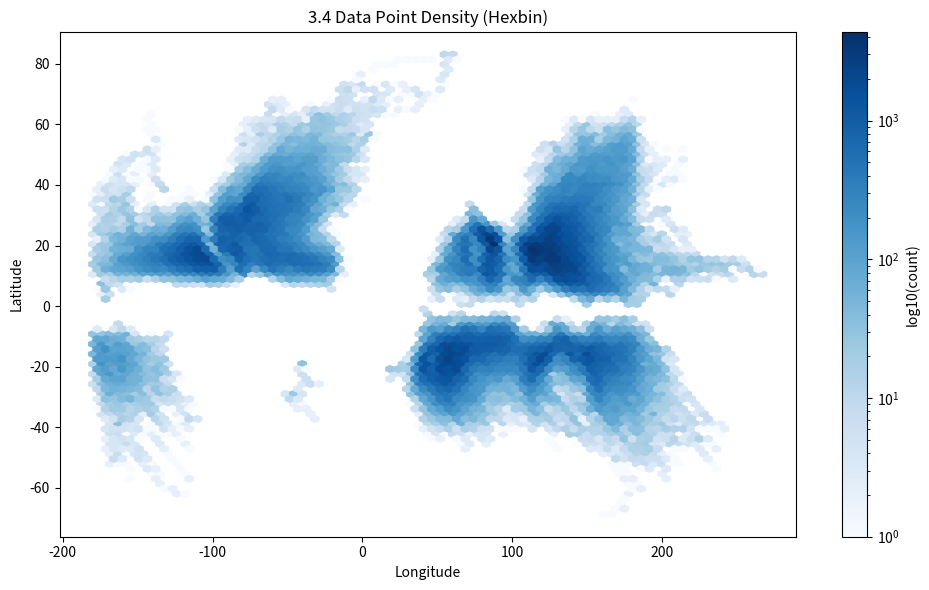

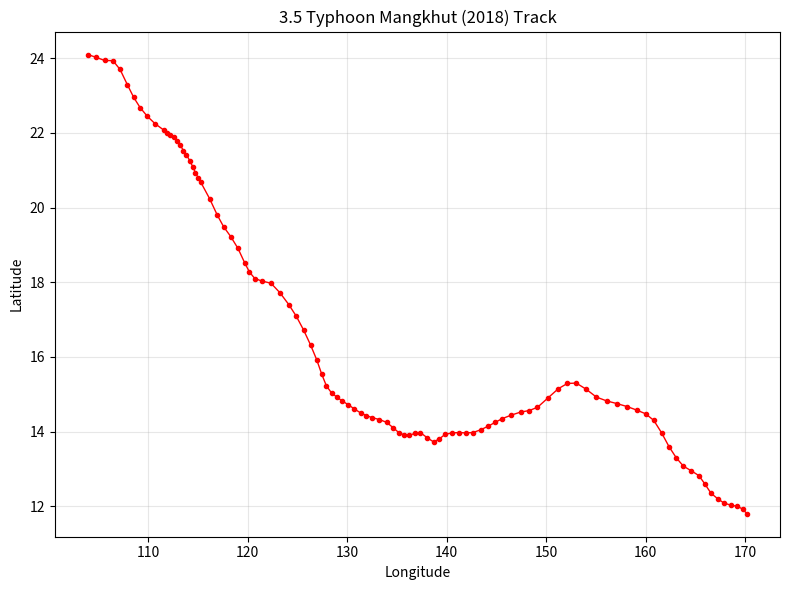


3.6 筛选后数据量：176352


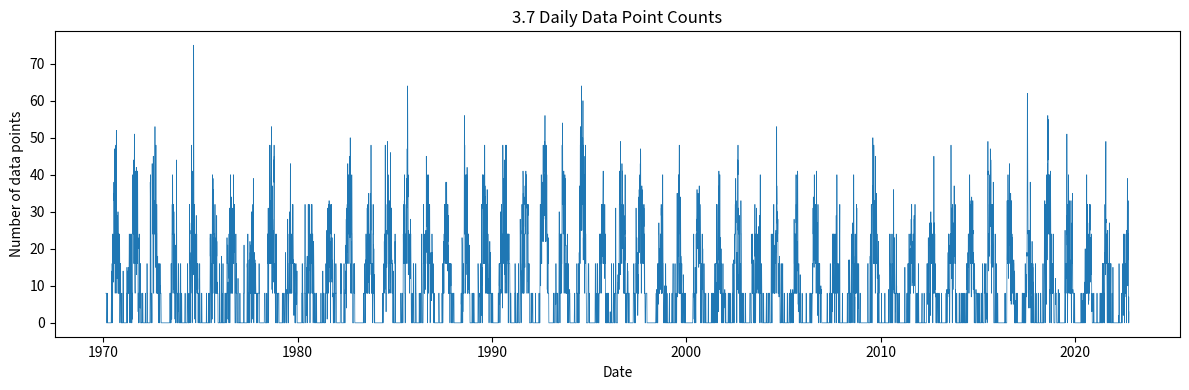

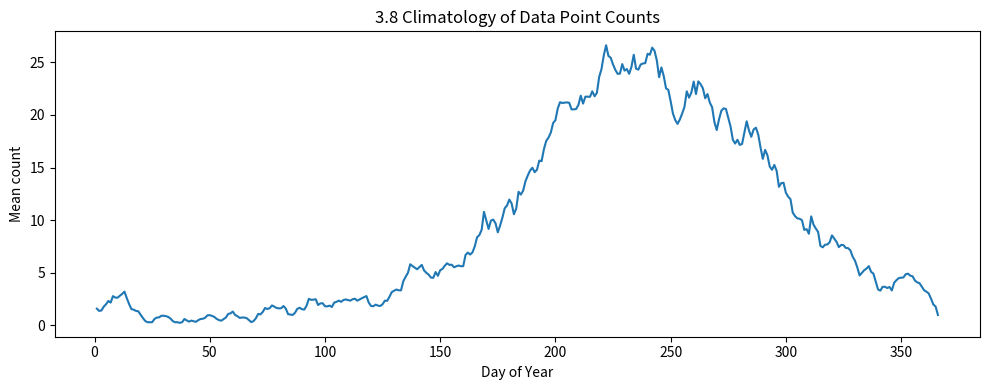

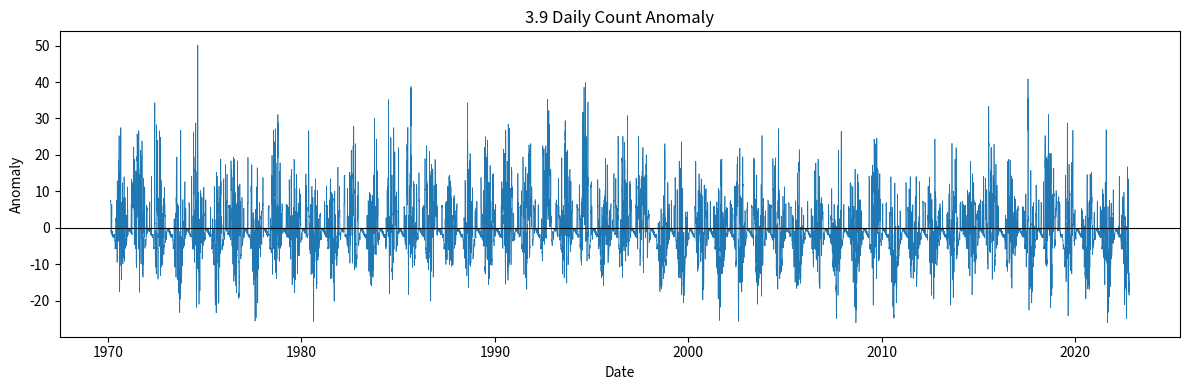

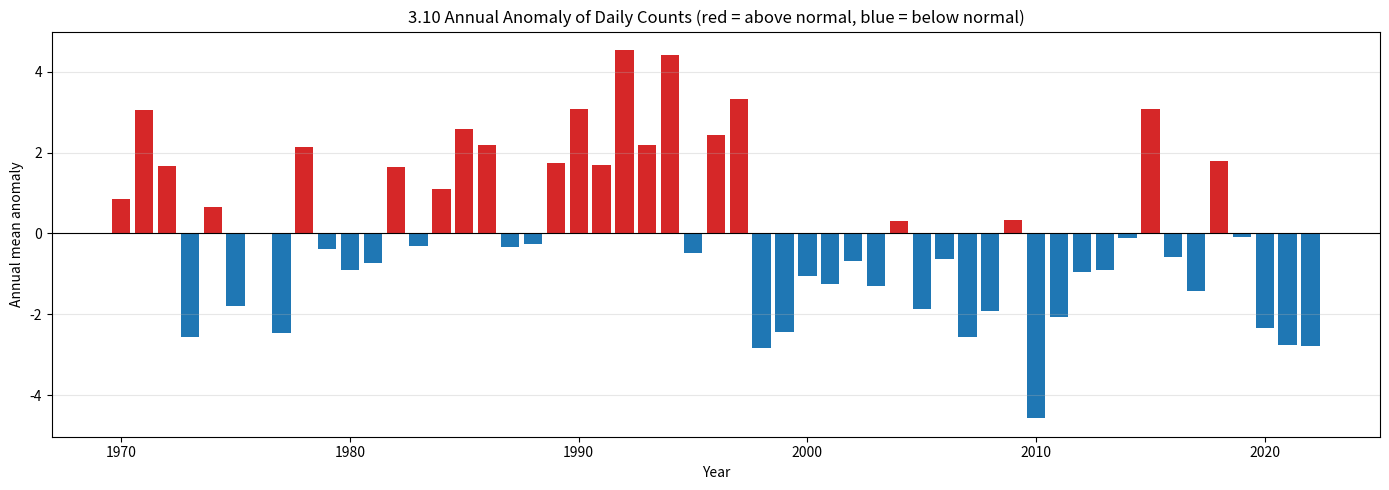


3.10 异常最显著的年份（按绝对值）：
ISO_TIME
2010-12-31    4.570616
1992-12-31    4.537501
1994-12-31    4.415686
1997-12-31    3.330754
1990-12-31    3.073220
2015-12-31    3.067741
1971-12-31    3.065001
1998-12-31    2.830890
2022-12-31    2.793204
2021-12-31    2.751437
dtype: float64


In [9]:
#导入
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#把字符串 'NOT_NAMED' 和 'NAME' 当作缺失值（NaN）处理
df = pd.read_csv("/home/zhangp/桌面/A2/ibtracs.ALL.list.v04r00.csv",  # 助教更改读取路径
                 usecols=range(17),
                 skiprows=[1],
                 parse_dates=['ISO_TIME'],
                 na_values=['NOT_NAMED', 'NAME'])

#把这三列强制转为数值型，将无法转换的值（空字符串、空格等）变成 NaN 
for col in ['WMO_WIND', 'LAT', 'LON']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    
#3.1取 WMO_WIND 的最大值，删除 MAX_WIND 为 NaN 的风暴，按 MAX_WIND 降序取前 10 名
storm_max = df.groupby('SID').agg(
    NAME=('NAME', 'first'),
    MAX_WIND=('WMO_WIND', 'max')
).dropna(subset=['MAX_WIND'])

top10 = storm_max.nlargest(10, 'MAX_WIND')
print("3.1 前10强飓风：")
print(top10[['NAME', 'MAX_WIND']])

#3.2从每个风暴的最大风速中取前 20 个值
top20_winds = storm_max['MAX_WIND'].nlargest(20).values
print("\n3.2 前20最强风速值：")
print(top20_winds)

#3.3统计 BASIN 列每个海盆（WP、EP、NA、SI 等）出现的记录数
basin_counts = df['BASIN'].value_counts()
print("\n3.3 各海盆数据点数量：")
print(basin_counts)

#3.4画图
fig, ax = plt.subplots(figsize=(10, 6))
hb = ax.hexbin(df['LON'], df['LAT'],
               gridsize=80, cmap='Blues', bins='log', mincnt=1)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('3.4 Data Point Density (Hexbin)')
plt.colorbar(hb, ax=ax, label='log10(count)')
plt.tight_layout()
plt.savefig('3_4_hexbin.png', dpi=100)
plt.show()

#3.5筛选出名字为 MANGKHUT 的所有记录，再筛选 2018 年的那条，并按时间排序
mangkhut = df[df['NAME'] == 'MANGKHUT']
mangkhut_2018 = mangkhut[mangkhut['ISO_TIME'].dt.year == 2018].sort_values('ISO_TIME')

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(mangkhut_2018['LON'], mangkhut_2018['LAT'],
        marker='o', markersize=3, linewidth=1, color='red')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('3.5 Typhoon Mangkhut (2018) Track')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('3_5_mangkhut.png', dpi=100)
plt.show()

#3.6保留两个条件同时满足的行：年份 ≥ 1970，且海盆是 WP或EP
df_filt = df[(df['ISO_TIME'].dt.year >= 1970) &
             (df['BASIN'].isin(['WP', 'EP']))].copy()
print(f"\n3.6 筛选后数据量：{len(df_filt)}")

daily_counts = df_filt.set_index('ISO_TIME').resample('D').size()
#daily_counts = daily_counts[daily_counts > 0] 应该保留计数点为0的天数不然平均值会偏大

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily_counts.index, daily_counts.values, linewidth=0.5)
ax.set_xlabel('Date')
ax.set_ylabel('Number of data points')
ax.set_title('3.7 Daily Data Point Counts')
plt.tight_layout()
plt.savefig('3_7_daily_counts.png', dpi=100)
plt.show()

#3.8提取每个日期是一年中的第几天（1~366），按 day-of-year 分组，对多年同一天的数据取平均，得到气候态，把索引补齐为 1~366，interpolate() 线性插值填补缺失值
doy = daily_counts.index.dayofyear
clim = daily_counts.groupby(doy).mean()
clim = clim.reindex(range(1, 367)).interpolate()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(clim.index, clim.values)
ax.set_xlabel('Day of Year')
ax.set_ylabel('Mean count')
ax.set_title('3.8 Climatology of Data Point Counts')
plt.tight_layout()
plt.savefig('3_8_climatology.png', dpi=100)
plt.show()

#3.9
clim_aligned = clim.reindex(daily_counts.index.dayofyear).values
#用每日实际计数减去对应日期的气候态，得到异常值
anomaly = pd.Series(daily_counts.values - clim_aligned,
                    index=daily_counts.index)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(anomaly.index, anomaly.values, linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Date')
ax.set_ylabel('Anomaly')
ax.set_title('3.9 Daily Count Anomaly')
plt.tight_layout()
plt.savefig('3_9_anomaly.png', dpi=100)
plt.show()

#3.10
#新版本 pandas（≥2.2）用 'YE'（year end），旧版本用 'A'，try/except 让代码在两种版本下都能运行
try:
    annual_anomaly = anomaly.resample('YE').mean()
except ValueError:
    annual_anomaly = anomaly.resample('A').mean()

fig, ax = plt.subplots(figsize=(14, 5))

years = annual_anomaly.index.year
values = annual_anomaly.values
colors = ['#d62728' if v > 0 else '#1f77b4' for v in values]

ax.bar(years, values, width=0.8, color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Year')
ax.set_ylabel('Annual mean anomaly')
ax.set_title('3.10 Annual Anomaly of Daily Counts (red = above normal, blue = below normal)')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('3_10_annual_anomaly.png', dpi=100)
plt.show()
#先取每年异常的绝对值 .abs()（偏多偏少都算"异常大"），再 .nlargest(10) 取最大的 10 个，得到异常最显著的 10 个年份
top_years = annual_anomaly.abs().nlargest(10)
print("\n3.10 异常最显著的年份（按绝对值）：")
print(top_years)

In [10]:
#3.3助教添加
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv(
    "/home/zhangp/桌面/A2/ibtracs.ALL.list.v04r00.csv",  # 助教更改读取路径
    usecols=range(17),
    skiprows=[1],
    parse_dates=["ISO_TIME"],
    keep_default_na=False,
    na_values=[" ", "NOT_NAMED"],
    low_memory=False,
)
basin_counts = df.groupby("BASIN").size().sort_values(ascending=False)
basin_counts

BASIN
WP    236576
SI    160668
NA    124881
SP     67119
EP     62412
NI     55402
SA       119
dtype: int64

### 代码运行正确且报告有相应分析，但是3.3缺少了NA名称的统计因为pandas默认NA为空值了-1，3.7不应该筛选掉计数为0的天数会导致3.8、3.9统计偏大-3

### 得分：46/50
### --------------------------------------------------------------------------------------------

In [6]:
#导入
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv('20261015_163935_calibration.csv')

df['tWvDateTime'] = pd.to_datetime(df['tWvDateTime'], errors='coerce')

print("原始:", df.shape)

# 删除时间解析失败的行
df = df[df['tWvDateTime'].notna()].copy()

# 保留 TotalIonCurrent 既非缺失、又大于 0 的行，剔除文件末尾被截断、总离子流不完整/为 0 的行
df = df[df['TotalIonCurrent'].notna() & (df['TotalIonCurrent'] > 0)].copy()

# 跳过时间列，其余列转为数值，无法转成数字的变成 NaN
for c in df.columns:
    if c != 'tWvDateTime':
        df[c] = pd.to_numeric(df[c], errors='coerce')

# 删除整列全是 NaN的列
df = df.dropna(axis=1, how='all')

# 构建要保留的列名列表 keep，先放入时间列，要求该列至少有一个非 NaN 值且绝对值之和大于 0，只保留keep中的列
keep = ['tWvDateTime']
for c in df.columns:
    if c != 'tWvDateTime' and df[c].notna().sum() > 0 and df[c].abs().sum() > 0:
        keep.append(c)
df_clean = df[keep].copy()

# 按时间升序排序，若同一时间戳出现多次，只保留第一次，重建连续行索引。
df_clean = (df_clean.sort_values('tWvDateTime')
            .drop_duplicates('tWvDateTime')
            .reset_index(drop=True))
#输出
print(f"清洗后: {df_clean.shape}")
print(f"有效通道数: {len(keep)-1}")
print(f"记录数: {len(df_clean)}")
print(f"时间: {df_clean['tWvDateTime'].min()} ~ {df_clean['tWvDateTime'].max()}")

原始: (1200, 2074)
清洗后: (1200, 2066)
有效通道数: 2065
记录数: 1200
时间: 2026-10-15 16:39:36.765000 ~ 2026-10-15 17:39:33.678000


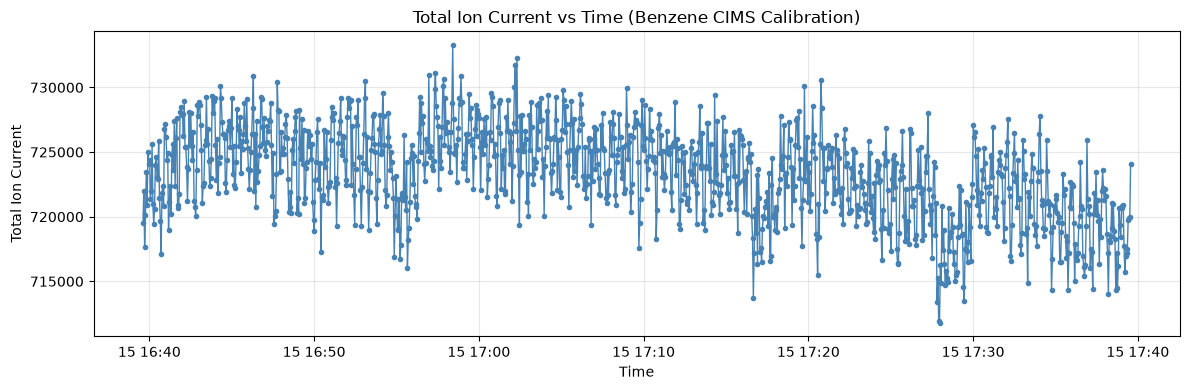

In [8]:

col = 'TotalIonCurrent'

# 创建 1 张图，尺寸 12x4 英寸
plt.figure(figsize=(12, 4))

# 画时间序列：X 为时间列，Y 为总离子流；'o-' 表示点+线，ms=3 点大小，lw=1 线宽
plt.plot(df_clean['tWvDateTime'], df_clean[col],
         'o-', ms=3, lw=1, color='steelblue')

# 设置 X 轴标签
plt.xlabel('Time')

# 设置 Y 轴标签
plt.ylabel('Total Ion Current')

# 设置标题
plt.title('Total Ion Current vs Time (Benzene CIMS Calibration)')

# 打开淡网格，alpha=0.3 透明度，不遮挡数据
plt.grid(alpha=0.3)

# 自动调整布局，避免标签被裁切
plt.tight_layout()

# 显示图形
plt.show()

In [10]:
x = df_clean['TotalIonCurrent'].values
n = len(x)

# 1. 描述统计
print("均值:", x.mean(), "标准差:", x.std(ddof=1),
      "最小:", x.min(), "最大:", x.max(), "CV:", x.std(ddof=1)/x.mean())

# 2. 正态检验
W, p = stats.shapiro(x)
print("Shapiro-Wilk p =", p)

# 3. 线性趋势检验
t = np.arange(n)
slope, _, r, p_slope, _ = stats.linregress(t, x)
print("斜率 =", slope, "R² =", r**2, "p =", p_slope)

# 4. 一阶自相关
rho1 = np.corrcoef(x[:-1], x[1:])[0, 1]
print("lag-1 自相关 =", rho1)

# 5. 前后时段均值差异
k = n // 3
tt, pt = stats.ttest_ind(x[:k], x[-k:], equal_var=False)
print("前1/3均值 =", x[:k].mean(), "后1/3均值 =", x[-k:].mean(), "p =", pt)

均值: 723321.3664166667 标准差: 3500.5131473291663 最小: 711807.5 最大: 733264.75 CV: 0.0048394991629663936
Shapiro-Wilk p = 2.435729263973812e-06
斜率 = -4.852824677100471 R² = 0.23081752716519688 p = 2.578618913533982e-70
lag-1 自相关 = 0.6721604335942575
前1/3均值 = 724744.7975999999 后1/3均值 = 720944.888525 p = 3.253805513095546e-56


### 代码结果展示正确且有相应分析


### 得分：15/15
### --------------------------------------------------------------------------------------------
### 建议后续作业可以在文件夹中放入原始数据方便助教运行并检查代码